In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
np.random.seed(42)

In [2]:
iris = load_iris(as_frame=True)
df = iris.data.copy()
df.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
true_labels = iris.target  # only for optional comparison

print(df.shape)
df.head()

(150, 4)


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


In [4]:
X = StandardScaler().fit_transform(df)
X[:3]

array([[-0.90068117,  1.01900435, -1.34022653, -1.3154443 ],
       [-1.14301691, -0.13197948, -1.34022653, -1.3154443 ],
       [-1.38535265,  0.32841405, -1.39706395, -1.3154443 ]])

In [5]:
methods = ["single", "complete", "average", "ward"]
dist = pdist(X)  # Euclidean pairwise distances

results = {}
for m in methods:
    Z = linkage(X, method=m)
    c, _ = cophenet(Z, dist)
    results[m] = c

pd.Series(results, name="cophenetic_corr").sort_values(ascending=False).to_frame()

,cophenetic_corr
average,0.854361
single,0.830005
ward,0.822630
complete,0.751459


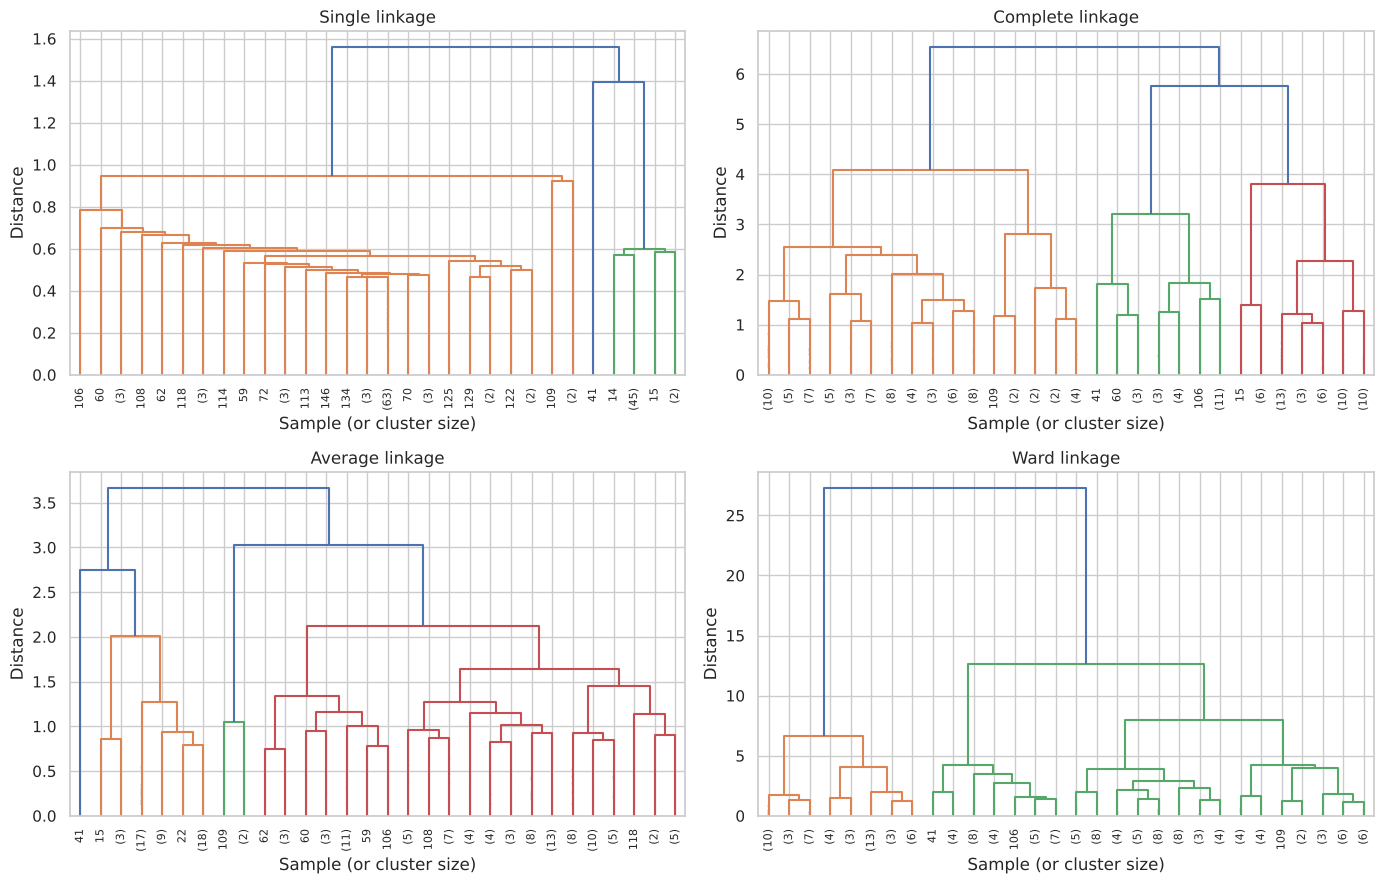

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, m in zip(axes.ravel(), methods):
    Z = linkage(X, method=m)
    dendrogram(Z, truncate_mode="lastp", p=30, ax=ax,
               leaf_rotation=90, leaf_font_size=8, show_contracted=True)
    ax.set_title(f"{m.capitalize()} linkage")
    ax.set_xlabel("Sample (or cluster size)")
    ax.set_ylabel("Distance")
plt.tight_layout()
plt.show()

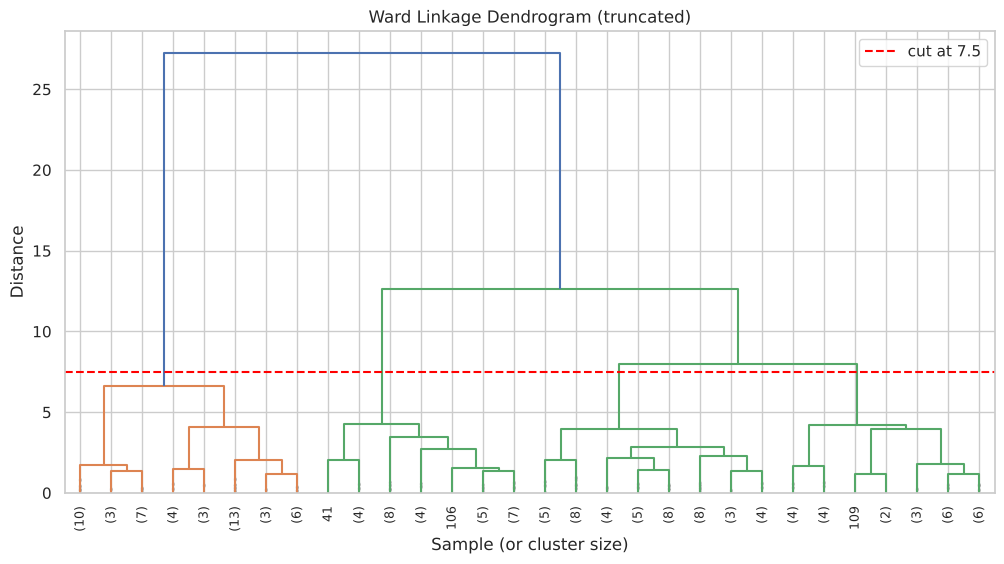

In [7]:
Z = linkage(X, method="ward")

plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90,
           leaf_font_size=9, show_contracted=True)
cut = 7.5
plt.axhline(y=cut, color="red", linestyle="--", label=f"cut at {cut}")
plt.title("Ward Linkage Dendrogram (truncated)")
plt.xlabel("Sample (or cluster size)")
plt.ylabel("Distance")
plt.legend()
plt.show()

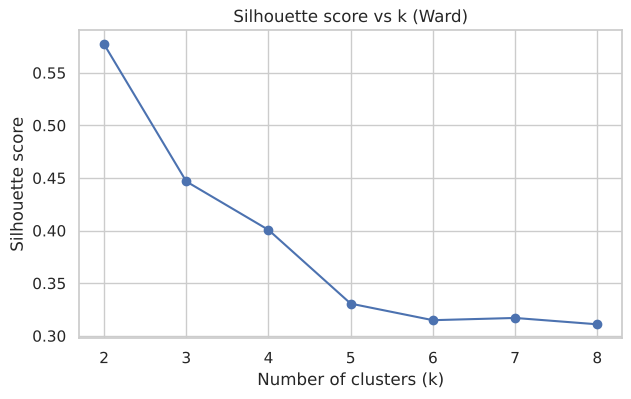

Silhouette scores: {2: np.float64(0.577), 3: np.float64(0.447), 4: np.float64(0.401), 5: np.float64(0.331), 6: np.float64(0.315), 7: np.float64(0.317), 8: np.float64(0.311)}
Best k by silhouette: 2


In [8]:
k_range = range(2, 9)
scores = []
for k in k_range:
    labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    scores.append(silhouette_score(X, labels))

plt.figure(figsize=(7, 4))
plt.plot(list(k_range), scores, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette score vs k (Ward)")
plt.show()

best_k = list(k_range)[int(np.argmax(scores))]
print("Silhouette scores:", dict(zip(k_range, np.round(scores, 3))))
print("Best k by silhouette:", best_k)

In [9]:
n_clusters = 3

model = AgglomerativeClustering(n_clusters=n_clusters, linkage="ward")
df["cluster"] = model.fit_predict(X)

print("Silhouette:", round(silhouette_score(X, df["cluster"]), 3))
df["cluster"].value_counts().sort_index()

Silhouette: 0.447


cluster
0    71
1    49
2    30
Name: count, dtype: int64

Equivalent result using SciPy's `fcluster` on the linkage matrix:

In [10]:
scipy_labels = fcluster(Z, t=n_clusters, criterion="maxclust") - 1
pd.crosstab(df["cluster"], scipy_labels, rownames=["sklearn"], colnames=["scipy"])

scipy,0,1,2
sklearn,,,
0,0,0,71
1,49,0,0
2,0,30,0


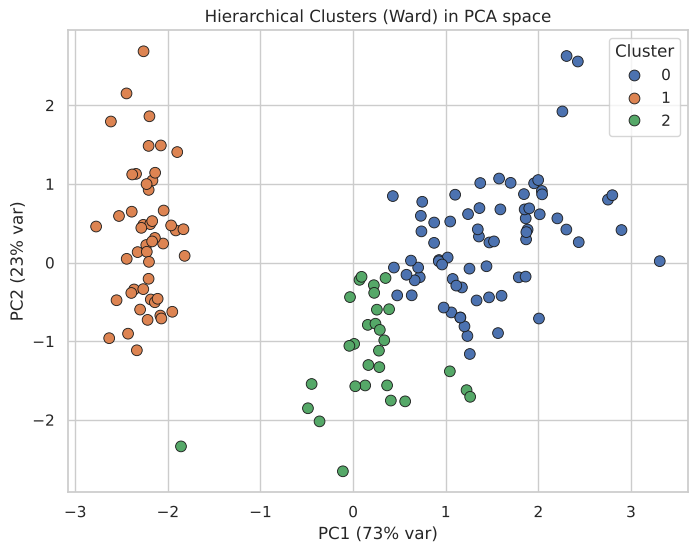

In [11]:
pca = PCA(n_components=2)
pcs = pca.fit_transform(X)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=df["cluster"],
                palette="deep", s=60, edgecolor="k")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} var)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} var)")
plt.title("Hierarchical Clusters (Ward) in PCA space")
plt.legend(title="Cluster")
plt.show()

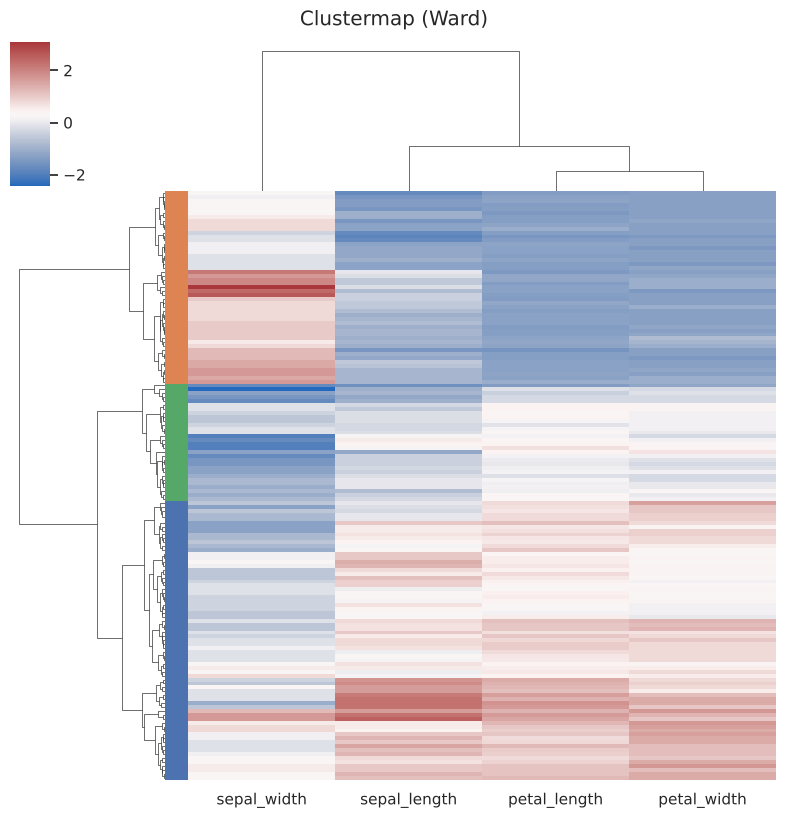

In [12]:
g = sns.clustermap(
    pd.DataFrame(X, columns=df.columns[:4]),
    method="ward", metric="euclidean", cmap="vlag",
    figsize=(8, 8), yticklabels=False,
    row_colors=df["cluster"].map(dict(zip(range(n_clusters), sns.color_palette("deep", n_clusters)))).values,
)
g.fig.suptitle("Clustermap (Ward)", y=1.02)
plt.show()

In [13]:
feature_cols = df.columns[:4]
profile = df.groupby("cluster")[feature_cols].mean().round(2)
profile

,sepal_length,sepal_width,petal_length,petal_width
cluster,,,,
0,6.55,2.99,5.27,1.85
1,5.02,3.45,1.47,0.24
2,5.53,2.57,3.93,1.21


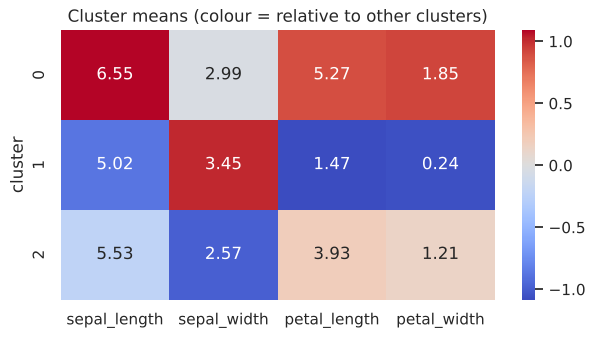

In [14]:
profile_z = (profile - profile.mean()) / profile.std()
plt.figure(figsize=(7, 3.5))
sns.heatmap(profile_z, annot=profile, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Cluster means (colour = relative to other clusters)")
plt.show()

In [15]:
from sklearn.metrics import adjusted_rand_score

print("Adjusted Rand Index:", round(adjusted_rand_score(true_labels, df["cluster"]), 3))
pd.crosstab(true_labels.map(dict(enumerate(iris.target_names))), df["cluster"],
            rownames=["species"], colnames=["cluster"])

Adjusted Rand Index: 0.615


cluster,0,1,2
species,,,
setosa,0,49,1
versicolor,23,0,27
virginica,48,0,2
